In [1]:
import numpy as np  # numeric arrays
import pandas as pd  # tables (DataFrame)
import matplotlib.pyplot as plt  # plotting
from sklearn.model_selection import train_test_split, cross_val_score  # split data, cross-validate
from sklearn.preprocessing import StandardScaler  # feature scaling
from sklearn.neighbors import KNeighborsClassifier  # the KNN model
from sklearn.metrics import accuracy_score  # evaluation tool


In [8]:
from google.colab import files  # Colab's file-upload helper
uploaded = files.upload()  # opens a Choose File dialog; pick Crop_recommendation.csv
df = pd.read_csv('Crop_recommendation.csv')  # load the CSV into a DataFrame
print('Shape:', df.shape)  # (rows, columns)
print('Number of crops:', df['label'].nunique())  # how many different classes
print('Records per crop:', df['label'].value_counts().unique())  # 100 for every crop = balanced
df.round(1).head()  # first 5 records


Saving Crop_recommendation.csv to Crop_recommendation (1).csv
Shape: (2200, 8)
Number of crops: 22
Records per crop: [100]


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.9,82.0,6.5,202.9,rice
1,85,58,41,21.8,80.3,7.0,226.7,rice
2,60,55,44,23.0,82.3,7.8,264.0,rice
3,74,35,40,26.5,80.2,7.0,242.9,rice
4,78,42,42,20.1,81.6,7.6,262.7,rice


Missing values: 0
              mean   min    max
N             50.6   0.0  140.0
P             53.4   5.0  145.0
K             48.1   5.0  205.0
temperature   25.6   8.8   43.7
humidity      71.5  14.3  100.0
ph             6.5   3.5    9.9
rainfall     103.5  20.2  298.6


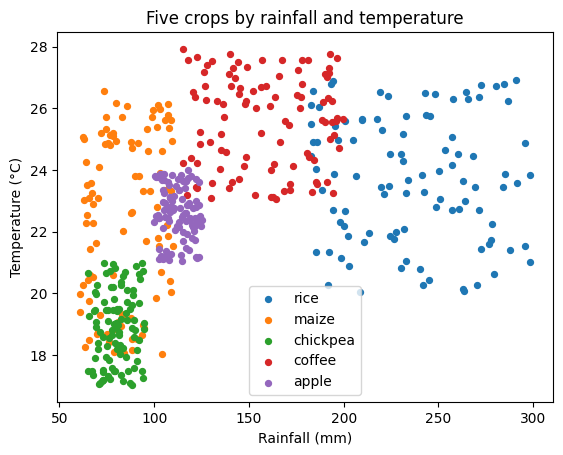

In [9]:
print('Missing values:', df.isnull().sum().sum())  # check for empty cells
print(df.describe().T[['mean', 'min', 'max']].round(1))  # range of every feature
chosen = ['rice', 'maize', 'chickpea', 'coffee', 'apple']  # 5 crops, to keep the plot readable
for crop in chosen:  # one colour per crop
    sub = df[df['label'] == crop]  # rows of this crop
    plt.scatter(sub['rainfall'], sub['temperature'], label=crop, s=18)  # rainfall vs temperature
plt.xlabel('Rainfall (mm)')
plt.ylabel('Temperature (°C)')
plt.title('Five crops by rainfall and temperature')
plt.legend()  # show crop names
plt.show()


In [10]:
X = df.drop('label', axis=1)  # 7 field measurements = input
y = df['label']  # crop name = output
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
        # 80% train / 20% test, same class ratio in both
scaler = StandardScaler()  # create the scaler (mean 0, std 1)
X_train_s = scaler.fit_transform(X_train)  # learn scaling from TRAIN data and apply it
X_test_s = scaler.transform(X_test)  # apply the SAME scaling to test data
print('Train:', X_train_s.shape, '| Test:', X_test_s.shape)  # check sizes
print('Std of first scaled feature:', round(X_train_s[:, 0].std(), 2))  # should be 1.0


Train: (1760, 7) | Test: (440, 7)
Std of first scaled feature: 1.0


In [11]:
knn = KNeighborsClassifier(n_neighbors=5)  # KNN that checks 5 nearest neighbours
knn.fit(X_train_s, y_train)  # 'training' just stores the data
print('K =', knn.n_neighbors, '| metric =', knn.metric, '| p =', knn.p)  # show the settings


K = 5 | metric = minkowski | p = 2


In [12]:
y_pred = knn.predict(X_test_s)  # each test field gets the majority crop of its 5 neighbours
acc = accuracy_score(y_test, y_pred)  # fraction of correct predictions
print('Accuracy:', round(acc, 4))
wrong = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
    # actual vs predicted crop for every test field
print('Wrong predictions:', (wrong['Actual'] != wrong['Predicted']).sum(), 'of', len(wrong))
    # count the mistakes
print(wrong[wrong['Actual'] != wrong['Predicted']])  # list only the mistakes


Accuracy: 0.9795
Wrong predictions: 9 of 440
         Actual    Predicted
4        orange  pomegranate
26    mothbeans        mango
154   mothbeans       lentil
186      orange      coconut
317  pigeonpeas    mothbeans
364  pigeonpeas  kidneybeans
378        rice         jute
434   mothbeans       lentil
435       maize       cotton


Best K: 1 | CV accuracy: 0.9705


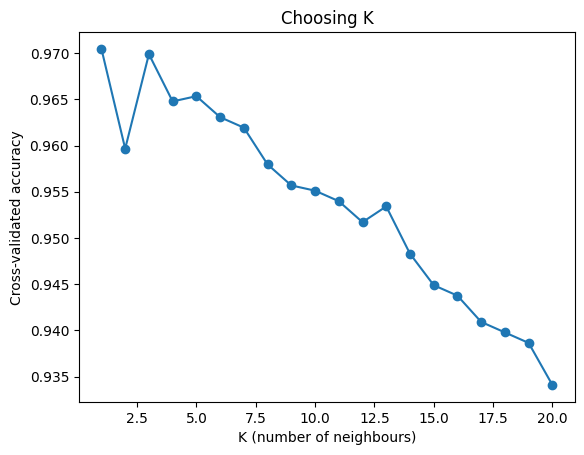

In [13]:
k_values = range(1, 21)  # try K = 1 to 20
cv_scores = []  # list to store the scores
for k in k_values:  # repeat for every K
    model = KNeighborsClassifier(n_neighbors=k)  # KNN with this K
    score = cross_val_score(model, X_train_s, y_train, cv=5).mean()  # average accuracy over 5 folds
    cv_scores.append(score)  # store it
best_k = k_values[int(np.argmax(cv_scores))]  # K with the highest score
print('Best K:', best_k, '| CV accuracy:', round(max(cv_scores), 4))
plt.plot(k_values, cv_scores, marker='o')  # accuracy vs K
plt.xlabel('K (number of neighbours)')
plt.ylabel('Cross-validated accuracy')
plt.title('Choosing K')
plt.show()


In [14]:
new_field = pd.DataFrame([[90, 42, 43, 24.0, 82.0, 6.5, 200.0]], columns=X.columns)
    # N, P, K, temp, humidity, pH, rainfall
new_field_s = scaler.transform(new_field)  # scale it with the SAME scaler
print('Recommended crop:', knn.predict(new_field_s)[0])  # majority vote of 5 neighbours
dist, idx = knn.kneighbors(new_field_s)  # distances and positions of the 5 nearest fields
print('Distances:', dist[0].round(2))  # how far each neighbour is
print('Neighbour crops:', y_train.iloc[idx[0]].tolist())  # their crops — the majority wins


Recommended crop: jute
Distances: [0.34 0.39 0.42 0.43 0.47]
Neighbour crops: ['rice', 'jute', 'jute', 'jute', 'rice']
